# 🟢 ark-beta-mini-v1 — Image-to-Text

## 🔴 Imports

In [1]:
from pathlib import Path
from datetime import datetime
from contextlib import redirect_stdout
import matplotlib.pyplot as plt
import random, numpy as np, torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import sys
import json
import time

## ⚙️ Configuration

In [2]:
ROOT = Path.cwd()
if not (ROOT/'dataset').exists() and (ROOT/'ark-imagine'/'dataset').exists():
    ROOT=ROOT/'ark-imagine'
    
DATA=ROOT/'dataset'/'Alphabet_VISION_Dataset'
LOGS=ROOT/'logs'; LOGS.mkdir(exist_ok=True)
SELECTED_DATASETS=['mnist'] # Explicit allowlist; other folders are ignored

IMAGE_SIZE=28;
BATCH_SIZE=32;
EPOCHS=10;
LR=1e-3

WEIGHT_DECAY = 0.0

EARLY_STOPPING_PATIENCE = 5
MIN_DELTA = 1e-4

OPTIMIZER_NAME = "Adam"

DEVICE=torch.device('cpu'); torch.set_num_threads(2)
random.seed(42); np.random.seed(42); torch.manual_seed(42)

## 🗂️ Dataset — Image/Text Pairs

In [3]:
class PairedDataset(Dataset):
    
    def __init__(self, split):
        
        self.items=[]
        
        for name in SELECTED_DATASETS:
            folder=DATA/split/name
            
            if not folder.is_dir():
                raise FileNotFoundError(folder)
                
            for p in sorted(folder.rglob('*')):
                if p.suffix.lower() not in ('.png','.jpg','.jpeg','.bmp'):
                    continue
                    
                caption=p.with_suffix('.txt')
                if not caption.is_file():
                    continue
                    
                label=caption.read_text(encoding='utf-8').strip()
                
                if label not in [str(i) for i in range(10)]:
                    continue # MNIST v1 vocabulary
                    
                self.items.append((p,int(label)))
                
        if not self.items:
            raise ValueError(f'No labeled pairs in {split}: {SELECTED_DATASETS}')

            
    def __len__(self):
        return len(self.items)

        
    def __getitem__(self,i):
        p,label=self.items[i]
        
        with Image.open(p) as im:
            im=im.convert('L').resize((IMAGE_SIZE,IMAGE_SIZE))
            arr=np.asarray(im,dtype=np.float32).copy()/255.
                
        return torch.from_numpy(arr).unsqueeze(0), torch.tensor(label,dtype=torch.long)

## 🔄 DataLoaders


In [4]:
def loaders():
    return (
        DataLoader(
            PairedDataset('train'),
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0
        ),
        DataLoader(
            PairedDataset('valid'),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0
        ),
        DataLoader(
            PairedDataset('test'),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0
        )
    )

## 💾 Checkpointing — Save and Resume

In [5]:
def save_checkpoint(
    path,
    model,
    opt,
    epoch,
    best,
    history,
    training_start_time,
    elapsed_training_time,
    early_stopping_counter=0
):
    current_elapsed = (
        elapsed_training_time
        + (time.time() - training_start_time)
    )

    model_signature = {
        name: tuple(param.shape)
        for name, param in model.state_dict().items()
    }

    optimizer_config = {
        "name": type(opt).__name__,
        "param_groups": [
            {
                "lr": group["lr"],
                "weight_decay": group.get("weight_decay", 0.0),
                "betas": group.get("betas"),
                "eps": group.get("eps")
            }
            for group in opt.param_groups
        ]
    }

    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "model_signature": model_signature,
        "optimizer_config": optimizer_config,
        "epoch": epoch,
        "best_val_loss": best,
        "early_stopping_counter": early_stopping_counter,
        "history": history,
        "selected_datasets": SELECTED_DATASETS,
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate(),
        "elapsed_training_time": current_elapsed
    }, path)

    hours, remainder = divmod(int(current_elapsed), 3600)
    minutes, seconds = divmod(remainder, 60)

    print(f"💾 Checkpoint saved successfully: {path}")
    print(f"   Completed epochs: {epoch}")
    print(f"   Best validation loss: {best:.6f}")
    print(
        f"   Total accumulated training time: "
        f"{hours:02d}:{minutes:02d}:{seconds:02d}"
    )


def resume(path, model, opt):

    print("=" * 55)
    print("🔍 Checking for an existing checkpoint...")
    print(f"📁 Checkpoint path: {path}")

    if not path.exists():
        print("🆕 No checkpoint found.")
        print("🚀 Starting training from scratch.")
        print("=" * 55)

        return 0, float("inf"), [], 0.0, 0

    ck = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if (
        ck.get("selected_datasets") != SELECTED_DATASETS
        or ck.get("image_size") != IMAGE_SIZE
        or ck.get("batch_size") != BATCH_SIZE
    ):
        raise ValueError(
            "Checkpoint dataset/image/batch configuration differs."
        )

    # Check architecture compatibility.
    current_signature = {
        name: tuple(param.shape)
        for name, param in model.state_dict().items()
    }

    if ck.get("model_signature") != current_signature:
        raise ValueError(
            "Model architecture differs from checkpoint."
        )

    # Check optimizer compatibility before loading its state.
    saved_config = ck.get("optimizer_config")

    if saved_config is None:
        raise ValueError(
            "Checkpoint lacks optimizer metadata. "
            "Use a compatible checkpoint or start a new run."
        )

    current_config = {
        "name": type(opt).__name__,
        "param_groups": [
            {
                "lr": group["lr"],
                "weight_decay": group.get("weight_decay", 0.0),
                "betas": group.get("betas"),
                "eps": group.get("eps")
            }
            for group in opt.param_groups
        ]
    }

    if saved_config != current_config:
        raise ValueError(
            "Optimizer settings differ from checkpoint.\n"
            f"Saved: {saved_config}\n"
            f"Current: {current_config}"
        )

    model.load_state_dict(ck["model_state_dict"])
    opt.load_state_dict(ck["optimizer_state_dict"])

    torch.set_rng_state(ck["rng_state"])
    np.random.set_state(ck["numpy_rng_state"])
    random.setstate(ck["python_rng_state"])

    last_epoch = ck["epoch"]
    best_loss = ck["best_val_loss"]
    history = ck["history"]

    elapsed_training_time = ck.get(
        "elapsed_training_time", 0.0
    )

    early_stopping_counter = ck.get(
        "early_stopping_counter", 0
    )

    hours, remainder = divmod(
        int(elapsed_training_time), 3600
    )
    minutes, seconds = divmod(remainder, 60)

    print("✅ Checkpoint loaded successfully.")
    print(f"   Last completed epoch: {last_epoch}")
    print(f"   Next epoch: {last_epoch + 1}")
    print(f"   Best validation loss: {best_loss:.6f}")
    print(f"   Recorded epochs: {len(history)}")
    print(f"   Early stopping counter: {early_stopping_counter}")
    print(
        f"   Previous training time: "
        f"{hours:02d}:{minutes:02d}:{seconds:02d}"
    )
    print("=" * 55)

    return (
        last_epoch,
        best_loss,
        history,
        elapsed_training_time,
        early_stopping_counter
    )

## 🧠 Model Architecture — BetaMini CNN

In [6]:
class BetaMini(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.net(x)


model = BetaMini().to(DEVICE)

print("=" * 55)
print("🚀 Model: ARK Beta Mini v1")
print(f"🧠 Model initialized on {DEVICE}")
print(f"🔢 Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"🖼️ Input image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print("🎯 Output classes: 10")
print("🏗️ Architecture: Convolutional Neural Network (CNN)")
print("✅ Model initialization completed successfully.")
print("=" * 55)

🚀 Model: ARK Beta Mini v1
🧠 Model initialized on cpu
🔢 Trainable parameters: 52,138
🖼️ Input image size: 28x28
🎯 Output classes: 10
🏗️ Architecture: Convolutional Neural Network (CNN)
✅ Model initialization completed successfully.


## 🏋️ Training and Validation

In [7]:
# =========================================================
# 1. Create a unique, timestamped directory for this run
# =========================================================

MODEL_NAME = "ark-beta-mini-v1"

MODEL_LOGS = ROOT / "logs" / MODEL_NAME
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
RUN_DIR = MODEL_LOGS / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

CHECKPOINT_DIR = RUN_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "best.pt"

LOG_PATH = RUN_DIR / "training.log"
HISTORY_PATH = RUN_DIR / "history.json"
PLOT_PATH = RUN_DIR / "training_plot.png"

# Find the best checkpoint from previous runs
previous_best_checkpoints = sorted(
    MODEL_LOGS.glob("*/checkpoints/best.pt"),
    key=lambda p: p.stat().st_mtime
)

previous_checkpoint = (
    previous_best_checkpoints[-1]
    if previous_best_checkpoints
    else None
)

resume_path = (
    previous_checkpoint
    if previous_checkpoint is not None
    else BEST_PATH
)

if previous_checkpoint is not None:
    print(f"🏆 Resuming from best checkpoint: {resume_path}")
else:
    print("🆕 No previous best checkpoint found.")

# =========================================================
# 2. Send console output to both terminal and log file
# =========================================================

class Tee:
    def __init__(self, *streams):
        self.streams = streams

    def write(self, message):
        for stream in self.streams:
            stream.write(message)
            stream.flush()

    def flush(self):
        for stream in self.streams:
            stream.flush()


# =========================================================
# 3. Initialize model and optimizer
# =========================================================

with open(LOG_PATH, "a", encoding="utf-8") as log_file:
    with redirect_stdout(Tee(sys.stdout, log_file)):

        print("=" * 65)
        print(f"🚀 Model: {MODEL_NAME}")
        print(f"📅 Run ID: {RUN_ID}")
        print(f"📁 Run directory: {RUN_DIR}")
        print(f"🖥️ Device: {DEVICE}")
        print(f"🔢 Requested additional epochs: {EPOCHS}")
        print("=" * 65)

        model = BetaMini().to(DEVICE)
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=LR,
            weight_decay=WEIGHT_DECAY
        )

        # Resume from the best previous checkpoint, if available.
        resume_path = (
            previous_checkpoint
            if previous_checkpoint is not None
            else BEST_PATH
        )

        (
            start,
            best,
            history,
            elapsed_training_time,
            early_stopping_counter
        ) = resume(
            resume_path,
            model,
            optimizer
        )
        
        # Start timing this training session.
        training_start_time = time.time()

        # Load datasets
        print("\n📚 Loading datasets...")
        
        train_loader, valid_loader, test_loader = loaders()

        print(f"Training batches: {len(train_loader)}")
        print(f"Validation batches: {len(valid_loader)}")
        print(f"Test batches: {len(test_loader)}")
        print("\n🏋️ Starting training...")

        # =================================================
        # 4. Training and validation
        # =================================================
        
        for epoch in range(start, start + EPOCHS):
        
            model.train()
            tr = 0.0
            count = 0
        
            for x, y in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
        
                optimizer.zero_grad()
                loss = nn.functional.cross_entropy(model(x), y)
                loss.backward()
                optimizer.step()
        
                tr += loss.item() * len(y)
                count += len(y)
        
            if count == 0:
                raise ValueError("Training dataset is empty.")
        
            model.eval()
            vl = 0.0
            correct = 0
            total = 0
        
            with torch.no_grad():
                for x, y in valid_loader:
                    x, y = x.to(DEVICE), y.to(DEVICE)
                    out = model(x)
        
                    vl += nn.functional.cross_entropy(
                        out, y, reduction="sum"
                    ).item()
        
                    correct += (out.argmax(1) == y).sum().item()
                    total += len(y)
        
            if total == 0:
                raise ValueError("Validation dataset is empty.")
        
            val = vl / total
            accuracy = correct / total
        
            # Early stopping: improvement must exceed MIN_DELTA.
            improved_enough = val < best - MIN_DELTA
        
            if val < best:
                best = val
        
                # Save the best model separately.
                save_checkpoint(
                    BEST_PATH,
                    model,
                    optimizer,
                    epoch + 1,
                    best,
                    history,
                    training_start_time,
                    elapsed_training_time,
                    early_stopping_counter
                )
        
            if improved_enough:
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1
        
            row = {
                "epoch": epoch + 1,
                "train_loss": tr / count,
                "valid_loss": val,
                "valid_accuracy": accuracy
            }
        
            history.append(row)        
        
            # Save full history (including previous runs).
            with open(HISTORY_PATH, "w", encoding="utf-8") as f:
                json.dump(
                    history,
                    f,
                    ensure_ascii=False,
                    indent=2
                )
        
            # The new log contains only epochs trained in this run.
            print(
                f"Epoch {epoch + 1}: "
                f"train_loss={row['train_loss']:.4f}, "
                f"valid_loss={val:.4f}, "
                f"valid_accuracy={accuracy:.2%}, "
                f"early_stopping={early_stopping_counter}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )
        
            # Update plot using the complete history.
            epochs = [r["epoch"] for r in history]
            train_losses = [r["train_loss"] for r in history]
            valid_losses = [r["valid_loss"] for r in history]
            accuracies = [r["valid_accuracy"] * 100 for r in history]
        
            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
            axes[0].plot(epochs, train_losses, label="Train Loss")
            axes[0].plot(epochs, valid_losses, label="Validation Loss")
            axes[0].set_title("Training and Validation Loss")
            axes[0].set_xlabel("Epoch")
            axes[0].set_ylabel("Loss")
            axes[0].legend()
            axes[0].grid(True)
        
            axes[1].plot(epochs, accuracies, label="Validation Accuracy")
            axes[1].set_title("Validation Accuracy")
            axes[1].set_xlabel("Epoch")
            axes[1].set_ylabel("Accuracy (%)")
            axes[1].legend()
            axes[1].grid(True)
        
            fig.tight_layout()
            fig.savefig(PLOT_PATH, dpi=150)
            plt.close(fig)
        
            # Stop if validation loss has not improved sufficiently.
            if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
                print(
                    f"🛑 Early stopping triggered at Epoch {epoch + 1}. "
                    f"No significant validation improvement for "
                    f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
                )
                break

        # =================================================
        # 5. Final training time summary
        # =================================================

        total_training_time = (
            elapsed_training_time
            + (time.time() - training_start_time)
        )

        hours, remainder = divmod(
            int(total_training_time), 3600
        )
        minutes, seconds = divmod(remainder, 60)

        print("\n" + "=" * 65)
        print("✅ Training run completed.")
        print(f"🏆 Best checkpoint: {BEST_PATH}")
        print(f"🏆 Best checkpoint: {BEST_PATH}")
        print(f"📄 Training log: {LOG_PATH}")
        print(f"📊 History: {HISTORY_PATH}")
        print(f"📈 Plot: {PLOT_PATH}")
        print(f"🏆 Best validation loss: {best:.6f}")

        print(
            f"⏱️ Total accumulated training time: "
            f"{hours:02d}:{minutes:02d}:{seconds:02d}"
        )

        print(
            f"⏱️ Current session duration: "
            f"{int((time.time() - training_start_time) // 3600):02d}:"
            f"{int((time.time() - training_start_time) % 3600 // 60):02d}:"
            f"{int((time.time() - training_start_time) % 60):02d}"
        )

        print("=" * 65)

🏆 Resuming from best checkpoint: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-18_15-20-49\checkpoints\best.pt
🚀 Model: ark-beta-mini-v1
📅 Run ID: 2026-10-19_09-57-44
📁 Run directory: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-19_09-57-44
🖥️ Device: cpu
🔢 Requested additional epochs: 10
🔍 Checking for an existing checkpoint...
📁 Checkpoint path: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-18_15-20-49\checkpoints\best.pt
✅ Checkpoint loaded successfully.
   Last completed epoch: 20
   Next epoch: 21
   Best validation loss: 0.340730
   Recorded epochs: 18
   Early stopping counter: 3
   Previous training time: 00:00:40

📚 Loading datasets...
Training batches: 25
Validation batches: 7
Test batches: 7

🏋️ Starting training...
Epoch 21: train_loss=0.0877, valid_loss=0.3463, valid_accuracy=92.00%, early_stopping=4/5
💾 Checkpoint saved successfully: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-19_09-57-44\checkpoints\best.pt
   Completed epochs: 

## 🔴 Test

🏆 Evaluation checkpoint: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-19_09-57-44\checkpoints\best.pt
📦 Evaluation checkpoint: F:\pyvenv\ARK\ark-imagine\logs\ark-beta-mini-v1\2026-10-19_09-57-44\checkpoints\best.pt

🏆 Final Test Results
Test samples: 200
Test loss: 0.314437
Test accuracy: 89.50%


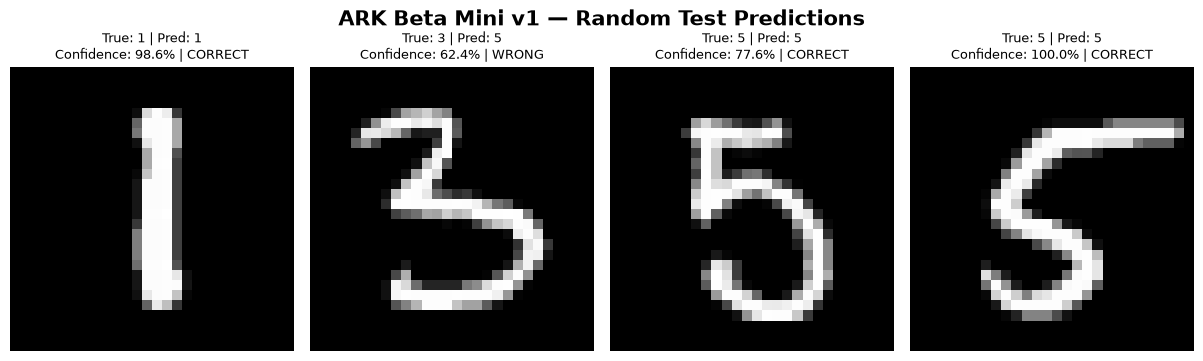


🔍 Random Test Sample Results
---------------------------------------------------------------------------
01. True=1 | Predicted=1 | Confidence=98.60% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\1_16.png
02. True=3 | Predicted=5 | Confidence=62.44% | ❌ WRONG
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\3_7.png
03. True=5 | Predicted=5 | Confidence=77.57% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\5_1.png
04. True=5 | Predicted=5 | Confidence=99.99% | ✅ CORRECT
    Image: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset\test\mnist\5_20.png
---------------------------------------------------------------------------
Random sample count: 4
Full test accuracy: 89.50%


In [8]:
# =========================================================
# 1. Load the best available checkpoint
# =========================================================

best_checkpoints = sorted(
    MODEL_LOGS.glob("*/checkpoints/best.pt"),
    key=lambda p: p.stat().st_mtime
)

if BEST_PATH.is_file():
    EVAL_PATH = BEST_PATH
elif best_checkpoints:
    EVAL_PATH = best_checkpoints[-1]
else:
    raise FileNotFoundError(
        "No best.pt checkpoint found."
    )

print(f"🏆 Evaluation checkpoint: {EVAL_PATH}")

checkpoint = torch.load(
    EVAL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print(f"📦 Evaluation checkpoint: {EVAL_PATH}")

checkpoint = torch.load(
    EVAL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()


# =========================================================
# 2. Evaluate the complete test dataset
# =========================================================

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits = model(x)

        test_loss += nn.functional.cross_entropy(
            logits,
            y,
            reduction="sum"
        ).item()

        test_correct += (
            logits.argmax(dim=1) == y
        ).sum().item()

        test_total += len(y)

if test_total == 0:
    raise ValueError("Test dataset is empty.")

test_loss /= test_total
test_accuracy = test_correct / test_total

print("\n" + "=" * 60)
print("🏆 Final Test Results")
print(f"Test samples: {test_total}")
print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print("=" * 60)


# =========================================================
# 3. Randomly select test images
# =========================================================

NUM_TEST_IMAGES = 4
RANDOM_SEED = None  # Use 42 for reproducible selections

test_dataset = test_loader.dataset

rng = random.Random(RANDOM_SEED)

num_samples = min(NUM_TEST_IMAGES, len(test_dataset))

selected_indices = rng.sample(
    range(len(test_dataset)),
    num_samples
)

images = []
true_labels = []
image_paths = []

for idx in selected_indices:
    image_tensor, label = test_dataset[idx]

    images.append(image_tensor)
    true_labels.append(label.item())
    image_paths.append(str(test_dataset.items[idx][0]))

x_batch = torch.stack(images).to(DEVICE)
y_true = torch.tensor(true_labels, dtype=torch.long)

# =========================================================
# 4. Predict randomly selected images
# =========================================================

with torch.no_grad():
    logits = model(x_batch)
    probabilities = torch.softmax(logits, dim=1)

    confidences, predictions = probabilities.max(dim=1)

predictions = predictions.cpu().numpy()
confidences = confidences.cpu().numpy()
images_np = x_batch.cpu().numpy()[:, 0]


# =========================================================
# 5. Visualize random test predictions
# =========================================================

cols = 4
rows = (num_samples + cols - 1) // cols

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(12, 3.5 * rows),
    squeeze=False,
    layout="constrained"
)

for i, ax in enumerate(axes.flat):

    if i >= num_samples:
        ax.axis("off")
        continue

    true_label = true_labels[i]
    predicted_label = int(predictions[i])
    confidence = float(confidences[i])

    ax.imshow(
        images_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    status = "CORRECT" if predicted_label == true_label else "WRONG"

    ax.set_title(
        f"True: {true_label} | Pred: {predicted_label}\n"
        f"Confidence: {confidence:.1%} | {status}",
        fontsize=9
    )

    ax.axis("off")

fig.suptitle(
    "ARK Beta Mini v1 — Random Test Predictions",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# =========================================================
# 6. Print individual prediction results
# =========================================================

print("\n" + "=" * 75)
print("🔍 Random Test Sample Results")
print("-" * 75)

for i in range(num_samples):
    status = (
        "✅ CORRECT"
        if predictions[i] == true_labels[i]
        else "❌ WRONG"
    )

    print(
        f"{i + 1:02d}. "
        f"True={true_labels[i]} | "
        f"Predicted={predictions[i]} | "
        f"Confidence={confidences[i]:.2%} | "
        f"{status}"
    )

    print(f"    Image: {image_paths[i]}")

print("-" * 75)
print(f"Random sample count: {num_samples}")
print(f"Full test accuracy: {test_accuracy:.2%}")
print("=" * 75)